# Explore relationships among simulation responses
## Goal
Which responses move together, which oppose each other, and do alternatives have similar **outcome profiles**?

This standalone exploratory notebook uses response columns only for linear and nonlinear dependence, conditional associations, noise relationships, embeddings, clustering stability and objective tradeoffs. It does not train or change the surrogate models. Saved outputs are **synthetic demonstrations**, not findings about your simulator.

Response-derived clusters require known outcomes: they cannot directly serve as input features for predicting those same outcomes at unseen alternatives. If this exploration informs model choices, restrict it to development alternatives; opening final-test outcomes here consumes their independence.

## Setup
Use the same installed project environment as `Surrogate_Workflow.ipynb`. No additional dependencies are needed. Select response columns explicitly: never include IDs or input factors as response measurements. Supply a CSV/Parquet path, or leave it unset for the labeled demonstration.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from surrogate_lab.response_exploration import response_table, explore_responses, describe_clusters

DATA_PATH = None
RESPONSES = ["throughput", "energy", "delay", "reliability"]
GROUP_COLUMNS = ["alternative"]  # Prefer factor columns if different IDs share identical inputs.
REPETITION_COLUMN = "repetition"  # None for one-row-per-alternative summaries.
MAX_CLUSTERS = 6
SELECTED_K = 3  # Exploratory choice; inspect alternatives rather than assuming a true cluster count.
SEED = 2026
EXPORT = False
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})
from surrogate_lab.response_exploration import (
    relationship_diagnostics, partial_relationships, within_configuration_relationships,
    compare_response_structures, pareto_profiles,
)
PERMUTATIONS = 199  # Increase for finer p-value resolution; cost grows with response pairs and n².
BOOTSTRAPS = 200
SUBSAMPLE_REPEATS = 12
DBSCAN_EPS = 0.8  # Distance in standardized full response space; inspect a range.
DBSCAN_MIN_SAMPLES = 5
# Explicit domain decisions only. Leave empty until you know which directions are desirable.
OBJECTIVE_DIRECTIONS = {}  # Example: {"throughput": "max", "energy": "min", "delay": "min"}


## 1. Load the response table
The example has unequal repetition counts, including singletons. With real data, use one coherent simulator version/scenario. If starting from an already aggregated table, each row has count 1 here; original repetition uncertainty cannot be reconstructed from means alone.

In [2]:
if DATA_PATH is None:
    rng=np.random.default_rng(SEED)
    latent=rng.normal(size=(90,2))
    counts=rng.integers(1,9,size=90)
    idx=np.repeat(np.arange(90),counts)
    a,b=latent[idx].T
    raw=pd.DataFrame({"alternative":idx,"repetition":np.concatenate([np.arange(n) for n in counts]),
        "throughput":100+15*a+rng.normal(0,3,len(idx)),
        "energy":50+8*a+4*b+rng.normal(0,2,len(idx)),
        "delay":20-3*a+2*b+rng.normal(0,1,len(idx)),
        "reliability":.9+.02*b+rng.normal(0,.005,len(idx))})
    print("SYNTHETIC: continuous latent relationships; no planted discrete clusters.")
else:
    path=Path(DATA_PATH)
    raw=pd.read_parquet(path) if path.suffix.lower() in (".parquet", ".pq") else pd.read_csv(path)
    print("Source:",path.resolve())
display(raw.head())

SYNTHETIC: continuous latent relationships; no planted discrete clusters.


,alternative,repetition,throughput,energy,delay,reliability
0,0,0,86.245299,41.961320,23.550912,0.902719
1,0,1,83.449722,44.242330,21.689052,0.898354
2,0,2,84.793781,43.050261,23.308317,0.897971
3,0,3,83.490733,49.314837,22.751241,0.896862
4,0,4,86.253446,43.786048,22.774017,0.904290


## 2. Establish equal configuration weight
Aggregate response means before clustering. An alternative with eight repetitions gets the same weight as one with a single observation. Missing/nonfinite responses are rejected, not silently imputed. Different repetition counts still imply different precision; small counts warrant caution.

In [3]:
table=response_table(raw,RESPONSES,GROUP_COLUMNS,REPETITION_COLUMN)
means=table["means"]
display(pd.DataFrame({"configurations":[len(means)],"observations":[len(raw)],
    "min_repetitions":[table["counts"].min()],"max_repetitions":[table["counts"].max()],
    "singleton_configurations":[int((table["counts"]==1).sum())]}))
display(means.head())
display(np.sqrt(table["mean_variances"]).describe().loc[["count","mean","max"]].rename(index={"count":"configurations with measured SE"}))
result=explore_responses(means,MAX_CLUSTERS,SEED)
print("Constant responses excluded from PCA/clustering:",result["constant_responses"])

Constant responses excluded from PCA/clustering: []


/Users/ksmith/Desktop/pipeline/simulation_surrogate_lab/.venv/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/ksmith/Desktop/pipeline/simulation_surrogate_lab/.venv/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/ksmith/Desktop/pipeline/simulation_surrogate_lab/.venv/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


,configurations,observations,min_repetitions,max_repetitions,singleton_configurations
0,90,393,1,8,11


,throughput,energy,delay,reliability
alternative,,,,
0,85.109364,44.535036,23.039030,0.900348
1,69.931249,42.844092,27.991852,0.928504
2,109.850836,53.183523,16.510934,0.888095
3,94.635975,48.836692,20.899434,0.905181
4,98.890766,46.659993,19.933329,0.895152


,throughput,energy,delay,reliability
configurations with measured SE,79.000000,79.000000,79.000000,79.000000
mean,1.400489,0.872624,0.372053,0.002233
max,4.254052,3.328270,1.218794,0.005828


## 3. Response relationships
Pearson measures linear association; Spearman measures rank association. Both describe relationships between observed configuration means, not causation. Shared simulation noise can affect them. Responses with different units are standardized for PCA/clustering; correlation is already scale-invariant.

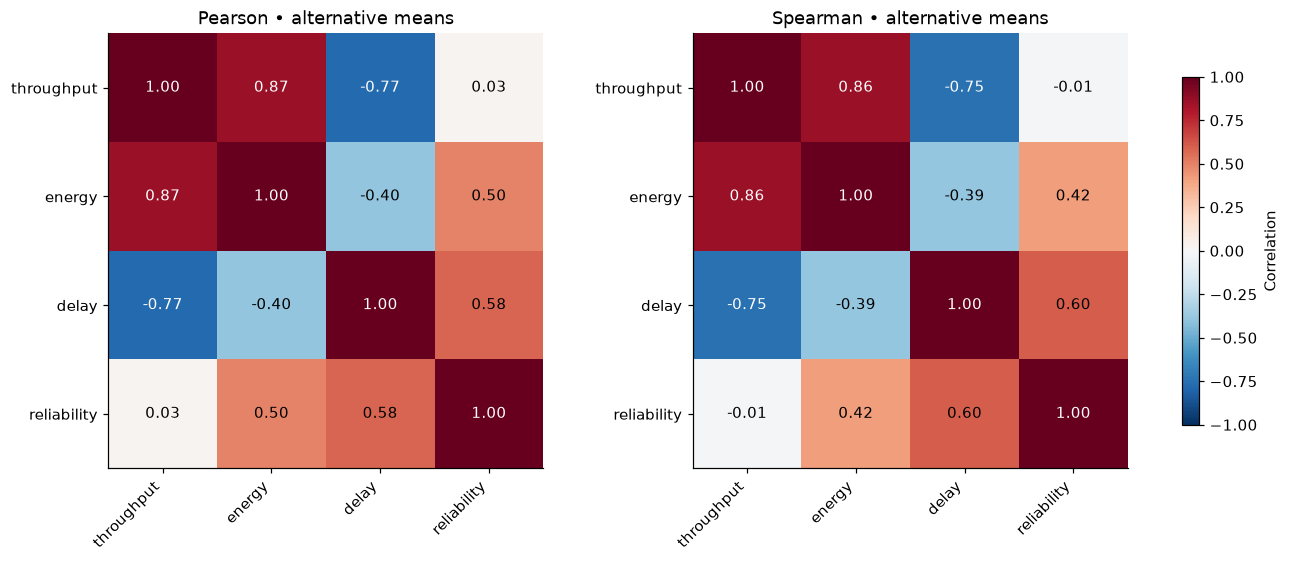

,level_0,level_1,spearman,absolute_correlation
1,throughput,energy,0.860065,0.860065
2,throughput,delay,-0.749763,0.749763
11,delay,reliability,0.603210,0.603210
7,energy,reliability,0.419945,0.419945
6,energy,delay,-0.385488,0.385488
3,throughput,reliability,-0.013804,0.013804
0,throughput,throughput,NaN,NaN
4,energy,throughput,NaN,NaN
5,energy,energy,NaN,NaN
8,delay,throughput,NaN,NaN


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,name in zip(axes,["pearson","spearman"]):
    matrix=result[name]
    im=ax.imshow(matrix,vmin=-1,vmax=1,cmap="RdBu_r")
    ax.set_xticks(range(len(matrix)),matrix.columns,rotation=45,ha="right")
    ax.set_yticks(range(len(matrix)),matrix.index)
    ax.set_title(name.title()+" • alternative means")
    if len(matrix)<=10:
        for i in range(len(matrix)):
            for j in range(len(matrix)): ax.text(j,i,f"{matrix.iloc[i,j]:.2f}",ha="center",va="center",color="white" if abs(matrix.iloc[i,j])>.65 else "black")
fig.colorbar(im,ax=axes,label="Correlation",shrink=.8)
plt.show()
pairs=result["spearman"].where(np.triu(np.ones(result["spearman"].shape),1).astype(bool)).stack().rename("spearman").reset_index()
pairs["absolute_correlation"]=pairs.spearman.abs()
display(pairs.sort_values("absolute_correlation",ascending=False).head(10))

## 4. Principal component analysis (PCA)
PCA summarizes variation in standardized response means using linear combinations. Explained variance shows how much the first components retain; axis coefficients identify contributing responses. Component signs are arbitrary. A two-dimensional projection can hide separation or overlap in omitted components.

First two PCs retain 99.2% of standardized response variance.


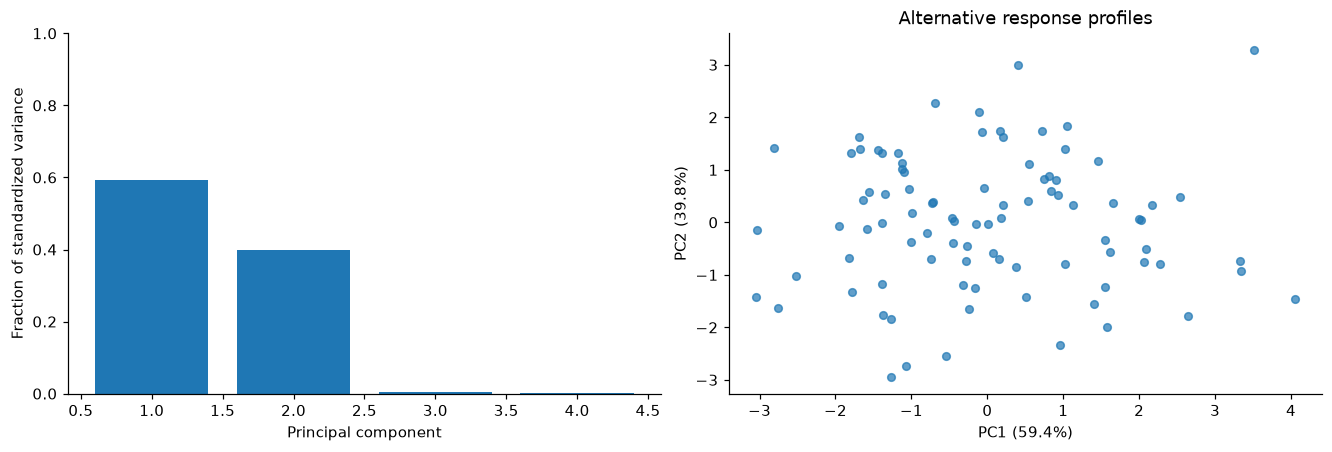

,PC1,PC2,PC3,PC4
Response axis coefficient,,,,
throughput,0.644714,0.033433,0.634988,-0.424284
energy,0.554415,0.406849,-0.104250,0.718491
delay,-0.526207,0.456654,0.674105,0.245267
reliability,-0.008632,0.790457,-0.362636,-0.493556


In [5]:
ratio=result["pca"].explained_variance_ratio_
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].bar(np.arange(1,len(ratio)+1),ratio)
axes[0].set(xlabel="Principal component",ylabel="Fraction of standardized variance",ylim=(0,1))
axes[1].scatter(result["scores"].PC1,result["scores"].PC2,s=25,alpha=.7)
axes[1].set(xlabel=f"PC1 ({ratio[0]:.1%})",ylabel=f"PC2 ({ratio[1]:.1%})",title="Alternative response profiles")
plt.show()
display(result["axes"].iloc[:,:min(4,len(ratio))].rename_axis("Response axis coefficient"))
print(f"First two PCs retain {ratio[:2].sum():.1%} of standardized response variance.")

## 5. Explore groupings without assuming they exist
K-means clusters alternatives in the **full standardized response space**, not just the two plotted PCs. It favors roughly compact groups. Silhouette compares within-group similarity with separation; cluster sizes expose tiny partitions. Initialization agreement (adjusted Rand index) checks sensitivity to random seeds, not evidence of natural populations. The synthetic example has no planted discrete groups, even if a silhouette score looks favorable.

Descriptive partition shown: 3 clusters; not an inferred true number of regimes.


,clusters,silhouette,smallest_cluster,inertia
0,2,0.354408,41,216.430740
1,3,0.340159,22,149.869838
2,4,0.356660,19,110.656756
3,5,0.370829,11,86.679457
4,6,0.384086,1,74.799841


,min,mean
clusters,,
2,0.869669,0.927260
3,0.966286,0.988762
4,0.847445,0.927961
5,0.851037,0.930560
6,0.611533,0.831807


cluster
0    22
1    40
2    28
Name: alternatives, dtype: int64

,throughput,energy,delay,reliability
cluster,,,,
0,121.031468,60.401569,15.127116,0.893624
1,96.929932,52.537863,22.644091,0.921084
2,89.138931,40.875922,20.421705,0.882517


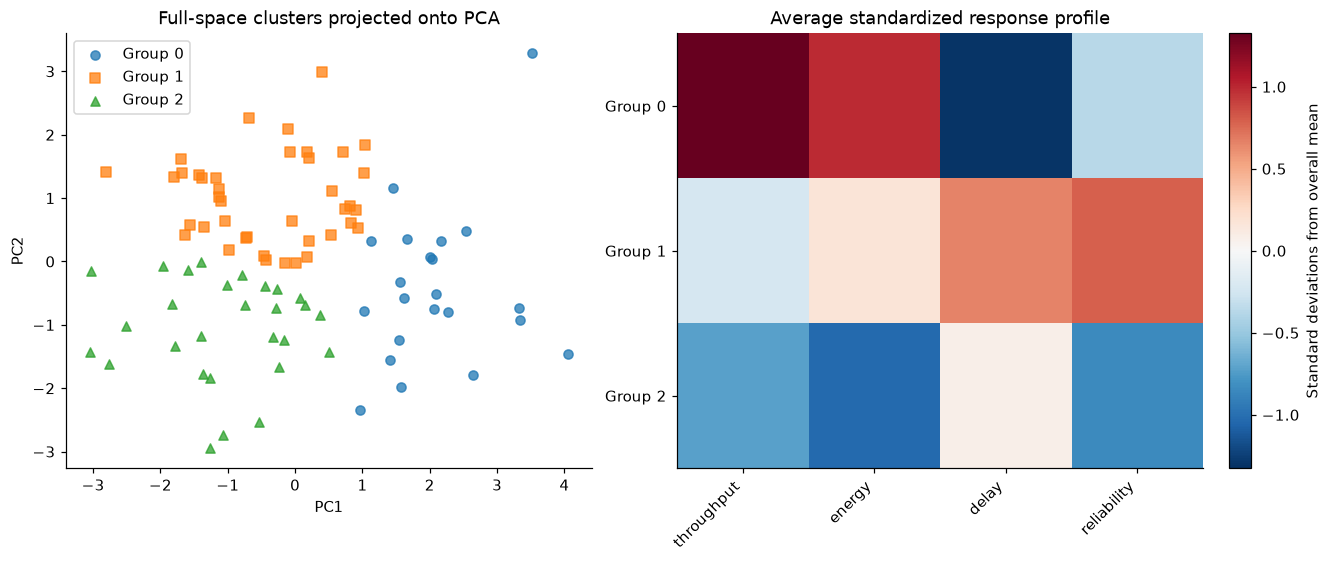

In [6]:
display(result["candidates"])
if not result["stability"].empty:
    display(result["stability"].groupby("clusters").adjusted_rand.agg(["min","mean"]))
if not result["models"]:
    raise ValueError("Not enough distinct response profiles to form meaningful candidate partitions.")
k=SELECTED_K if SELECTED_K in result["models"] else min(result["models"])
print("Descriptive partition shown:",k,"clusters; not an inferred true number of regimes.")
clusters=describe_clusters(result,k)
display(clusters["counts"].rename("alternatives"))
display(clusters["means"])
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for label in sorted(clusters["labels"].unique()):
    mask=clusters["labels"].to_numpy()==label
    axes[0].scatter(result["scores"].PC1[mask],result["scores"].PC2[mask],label=f"Group {label}",marker=["o","s","^","D","v","P"][label%6],alpha=.75)
axes[0].set(xlabel="PC1",ylabel="PC2",title="Full-space clusters projected onto PCA")
axes[0].legend()
profiles=clusters["standardized_means"]
limit=max(1,float(np.abs(profiles.to_numpy()).max()))
im=axes[1].imshow(profiles,vmin=-limit,vmax=limit,cmap="RdBu_r",aspect="auto")
axes[1].set_xticks(range(len(profiles.columns)),profiles.columns,rotation=45,ha="right")
axes[1].set_yticks(range(len(profiles)),[f"Group {i}" for i in profiles.index])
axes[1].set_title("Average standardized response profile")
fig.colorbar(im,ax=axes[1],label="Standard deviations from overall mean")
plt.show()

## 6. Check sensitivity to replication
Compare associations using only configurations with at least two observations. This changes the population and is not a correction for measurement error. Large changes warrant examining sampling design and noisy means. The following phases add alternative clustering methods and configuration subsampling. Initialization stability alone does not establish robust groups.

In [7]:
replicated=means.loc[table["counts"]>=2,result["active"].columns]
if len(replicated)>=3:
    change=replicated.corr(method="spearman")-result["spearman"]
    display(change.rename_axis("Replicated-only minus all-configurations Spearman"))
else:
    print("Too few replicated configurations for a separate association check.")
assignments=means.join(table["counts"]).join(clusters["labels"])
if EXPORT:
    destination=Path("response_exploration_results")
    destination.mkdir(exist_ok=True)
    assignments.to_csv(destination/"exploratory_response_groups.csv")
    result["axes"].to_csv(destination/"pca_axis_coefficients.csv")
    result["candidates"].to_csv(destination/"cluster_comparison.csv",index=False)
    print("Exported descriptive results to",destination.resolve())

,throughput,energy,delay,reliability
Replicated-only minus all-configurations Spearman,,,,
throughput,0.000000,-0.013205,-0.040670,-0.013119
energy,-0.013205,0.000000,-0.028339,0.002134
delay,-0.040670,-0.028339,0.000000,-0.029379
reliability,-0.013119,0.002134,-0.029379,0.000000


## 7. Inspect distributions before interpreting relationships
**Question:** are relationships driven by broad trends, a few extremes, or curved patterns?

Histograms show observed configuration means, not individual-run outcome distributions. The scatter matrix can expose U-shaped relationships that Pearson and Spearman miss. Limit the display to a manageable subset when there are many responses; all configured varying responses still enter the computations. Extreme profiles are investigation candidates, not automatic deletion targets.

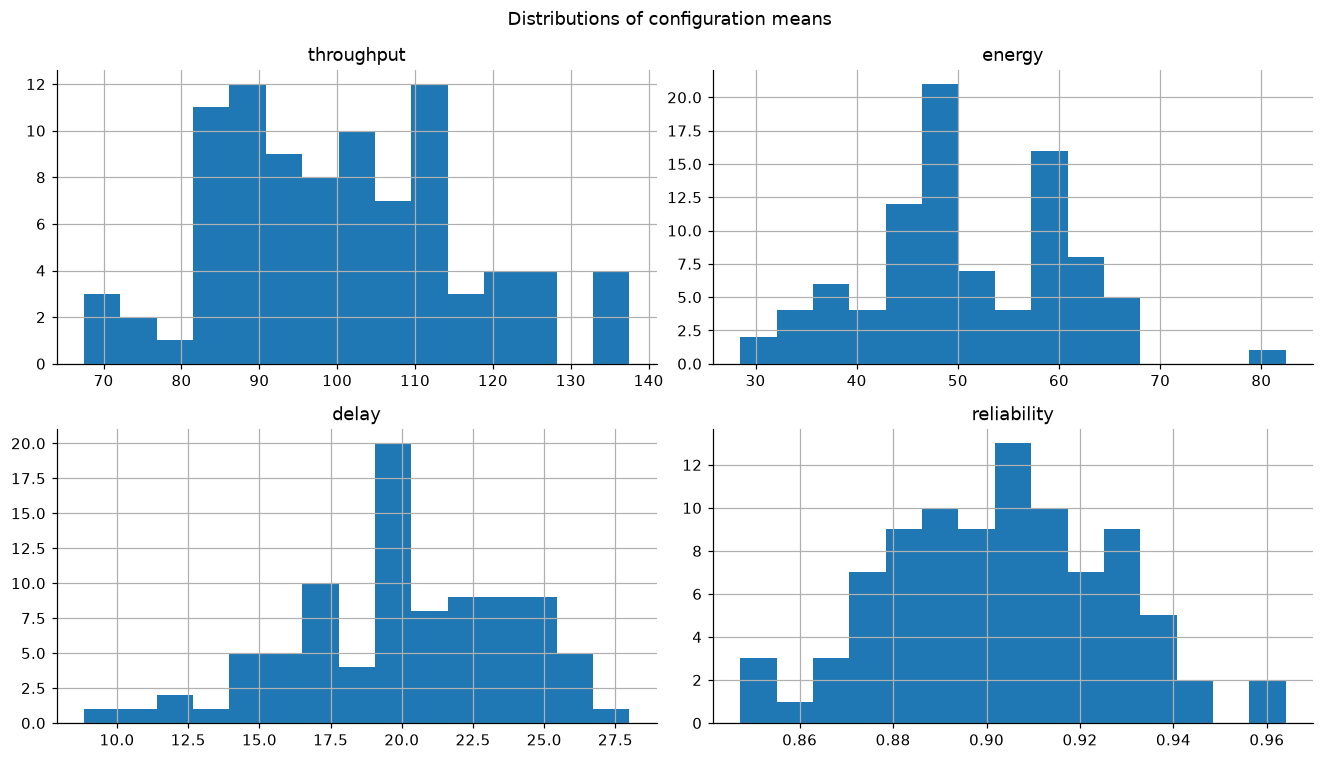

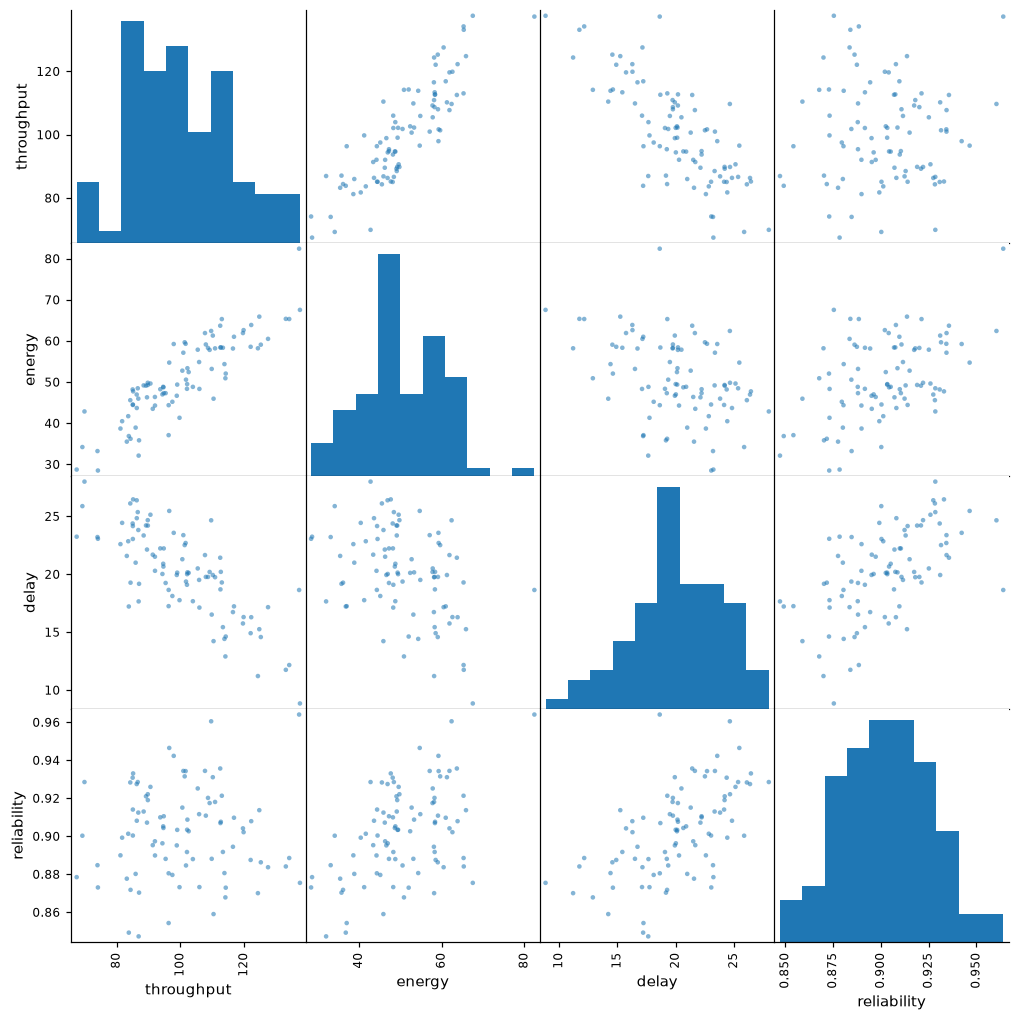

,throughput,energy,delay,reliability,max_absolute_z
alternative,,,,,
24,137.276445,82.411375,18.634952,0.964028,3.254033
82,137.534653,67.537348,8.839985,0.875436,2.944070
80,109.680200,62.414170,24.650418,0.960469,2.456990
69,86.923662,32.109595,17.649606,0.847273,2.330310
70,124.348656,58.197759,11.204687,0.870020,2.326623
46,74.146641,28.486159,23.056411,0.873023,2.302572
65,67.480895,28.721020,23.236475,0.878451,2.278371
55,83.839856,36.859565,17.211550,0.849237,2.247256
23,133.108647,65.355053,11.742929,0.884073,2.186082


In [8]:
active = result["active"]
active.hist(bins=15, figsize=(12, 7))
plt.suptitle("Distributions of configuration means")
plt.tight_layout()
plt.show()
pd.plotting.scatter_matrix(active.iloc[:, :min(6, active.shape[1])], figsize=(11, 11), diagonal="hist", alpha=.55)
plt.show()
# A transparent extremeness score, not an anomaly probability.
extremeness = pd.Series(np.max(np.abs(result["standardized"]), axis=1), index=means.index, name="max_absolute_z")
display(means.join(extremeness).sort_values("max_absolute_z", ascending=False).head(10))

## 8. Nonlinear dependence and design-composition sensitivity
**Question:** can two responses be related even when their correlation is near zero?

Distance correlation compares all pairwise distances for the two responses. It can detect curved dependence such as $Y=X^2$. It is nonnegative, does not indicate whether increasing one response improves another, and its sample estimate is positively biased. A permutation comparison helps distinguish observed dependence from this finite-sample baseline.

For each pair, shuffle one response across configurations and calculate
$p=(1+\#\{d_{perm}\geq d_{observed}\})/(B+1)$, where $B$ is the number of permutations. BH q-values adjust the pairwise testing family; they are exploratory, particularly with dependent tests. Exchangeability across configurations is an assumption: adaptive designs, spatial dependence and common random numbers can invalidate these p-values.

Pearson bootstrap ranges resample whole configuration mean rows. They show sensitivity to **which configurations were sampled**, conditional on their measured means. They are not confidence intervals for noiseless simulator relationships and do not resample repetitions. For example, a narrow positive range is more composition-stable than a range spanning both signs. Use more permutations for finer resolution; with 199 permutations the smallest p-value is 0.005.

,response_a,response_b,pearson,spearman,distance_correlation,permutation_p,pearson_bootstrap_low,pearson_bootstrap_high,valid_bootstraps,bh_q
0,throughput,energy,0.865902,0.860065,0.843474,0.005,0.812198,0.902512,200,0.006
1,throughput,delay,-0.773933,-0.749763,0.740765,0.005,-0.848960,-0.662571,200,0.006
2,delay,reliability,0.578538,0.603210,0.584370,0.005,0.457721,0.697359,200,0.006
3,energy,reliability,0.496945,0.419945,0.433322,0.005,0.302739,0.632353,200,0.006
4,energy,delay,-0.396943,-0.385488,0.403351,0.005,-0.551153,-0.247896,200,0.006
5,throughput,reliability,0.026429,-0.013804,0.175610,0.470,-0.211779,0.262246,200,0.470


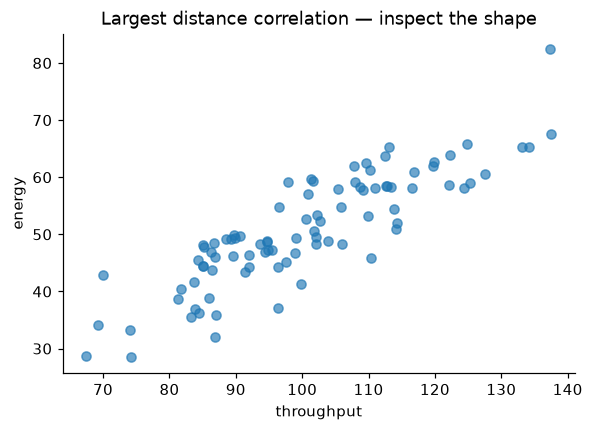

In [9]:
relationships = relationship_diagnostics(means, PERMUTATIONS, BOOTSTRAPS, SEED)
display(relationships)
# Inspect the strongest nonlinear association in original response units.
pair = relationships.iloc[0]
plt.figure(figsize=(6, 4))
plt.scatter(means[pair.response_a], means[pair.response_b], alpha=.65)
plt.xlabel(pair.response_a)
plt.ylabel(pair.response_b)
plt.title("Largest distance correlation — inspect the shape")
plt.show()

## 9. Associations after accounting for other responses
**Question:** does an apparent relationship persist after linear adjustment for the remaining responses?

A shrinkage covariance estimate stabilizes nearly redundant response sets. Its inverse $\Omega$ gives regularized partial correlations
$\rho_{ij\mid rest}=-\Omega_{ij}/\sqrt{\Omega_{ii}\Omega_{jj}}$.

For example, throughput and energy may correlate because both track a third response. A weaker partial association suggests shared linear structure; it does not establish the physical mechanism. Shrinkage changes the estimate, nonlinear dependence remains possible, and conditioning can introduce associations. These are neither causal edges nor conditional-independence tests. Compare with the marginal Pearson table before interpreting a sign change.

Estimated covariance shrinkage: 0.06212846706579449


,throughput,energy,delay,reliability
throughput,1.000000,0.641592,-0.517657,-0.010370
energy,0.641592,1.000000,-0.219937,0.663915
delay,-0.517657,-0.219937,1.000000,0.740727
reliability,-0.010370,0.663915,0.740727,1.000000


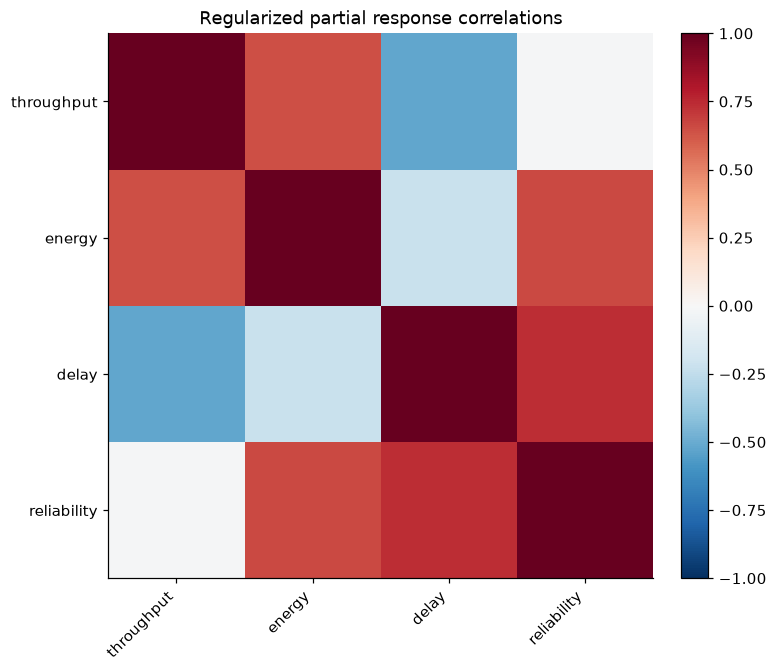

In [10]:
conditional = partial_relationships(means)
print("Estimated covariance shrinkage:", conditional["shrinkage"])
display(conditional["partial"])
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(conditional["partial"], vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(active.columns)), active.columns, rotation=45, ha="right")
ax.set_yticks(range(len(active.columns)), active.columns)
ax.set_title("Regularized partial response correlations")
fig.colorbar(im, ax=ax)
plt.show()

## 10. Separate configuration trends from shared simulation noise
**Question:** do responses move together because configurations differ, or because the same run affects both outcomes?

The earlier correlations compare configuration means. Here each replicated configuration supplies a sample covariance matrix from paired response measurements in its runs. We average these matrices with equal configuration weight and convert the average to correlations. Singletons contribute no covariance estimate and are excluded explicitly.

If throughput and energy correlate across configurations but not within configurations, their relationship may predominantly reflect differences in operating conditions. If both correlations are strong, shared stochastic variation may also contribute. These are different estimands: within-configuration covariance is not subtracted from the original correlations. Independent repetitions and correctly paired run outcomes are required; common seeds across configurations need a separate covariance-aware analysis.

In [11]:
within = within_configuration_relationships(raw, RESPONSES, GROUP_COLUMNS, REPETITION_COLUMN)
print("Replicated configurations contributing:", within["replicated_configurations"])
display(within["correlation"].rename_axis("Within-configuration run correlation"))
display(result["pearson"].rename_axis("Between observed configuration means"))

Replicated configurations contributing: 79


,throughput,energy,delay,reliability
Within-configuration run correlation,,,,
throughput,1.000000,-0.068900,0.043191,-0.007080
energy,-0.068900,1.000000,0.034603,-0.019183
delay,0.043191,0.034603,1.000000,0.016580
reliability,-0.007080,-0.019183,0.016580,1.000000


,throughput,energy,delay,reliability
Between observed configuration means,,,,
throughput,1.000000,0.865902,-0.773933,0.026429
energy,0.865902,1.000000,-0.396943,0.496945
delay,-0.773933,-0.396943,1.000000,0.578538
reliability,0.026429,0.496945,0.578538,1.000000


## 11. Compare different assumptions about response groups
**Question:** do groupings survive a change in algorithm and a change in the observed configurations?

| Method | What it looks for | Interpretation limit |
|---|---|---|
| K-means | Compact groups around centroids | Splits continuous clouds too |
| Ward hierarchy | Nested merges minimizing within-group variance | Cutting at k imposes k groups |
| Gaussian mixture | Overlapping ellipsoidal components | Components need not be physical regimes |
| DBSCAN | Dense regions separated by sparse space | Sensitive to radius, scaling and dimension; -1 is noise |

All methods use full standardized response space. K-means, Ward and GMM use the same selected k; DBSCAN uses an explicit radius. Silhouettes for DBSCAN exclude noise, so compare its retained fraction alongside its score. GMM BIC is meaningful only relative to other GMM specifications on the same data; it cannot rank these different algorithms.

Subsampling refits each scaler and estimator on 80% of configurations. Adjusted Rand agreement compares the subset partition with the corresponding full-data labels; label numbers themselves are arbitrary. Degenerate partitions are reported as unavailable. This is overlapping-data sensitivity, not independent validation or repetition uncertainty. Try several k values and DBSCAN radii before treating any partition as useful.

,method,groups,noise_fraction,silhouette_excluding_noise,smallest_group,bic
0,kmeans,3,0.000000,0.340159,22,NaN
1,ward,3,0.000000,0.351721,18,NaN
2,gmm,3,0.000000,0.141403,18,524.934067
3,dbscan,1,0.155556,NaN,76,NaN


,count,min,median,max
method,,,,
dbscan,0,NaN,NaN,NaN
gmm,12,0.101858,0.345043,0.717354
kmeans,12,0.214672,0.458213,1.000000
ward,12,0.207880,0.869566,1.000000


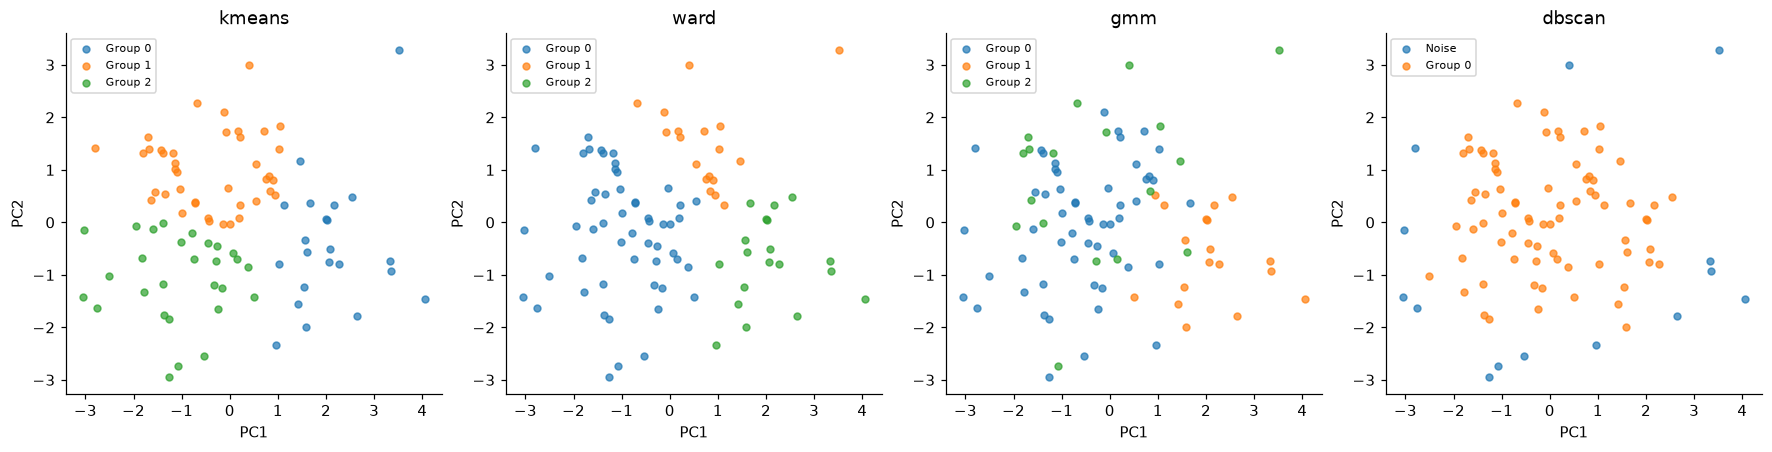

In [12]:
structures = None
if int(.8 * len(means)) > k:
    structures = compare_response_structures(means, k=k, seed=SEED,
        repeats=SUBSAMPLE_REPEATS, dbscan_eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES)
    display(structures["comparison"])
    display(structures["stability"].groupby("method").adjusted_rand.agg(["count", "min", "median", "max"]))
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
    for ax, method in zip(axes, structures["labels"]):
        labels = structures["labels"][method]
        for label in sorted(labels.unique()):
            mask = labels.to_numpy() == label
            ax.scatter(result["scores"].PC1[mask], result["scores"].PC2[mask], s=20, alpha=.7,
                       label="Noise" if label == -1 else f"Group {label}")
        ax.set(title=method, xlabel="PC1", ylabel="PC2")
        ax.legend(fontsize=7)
    plt.show()
else:
    print("Too few configurations for the requested k and subsampling fraction.")

## 12. Look beyond a linear projection
**Question:** does a nonlinear view reveal structure hidden by the first two PCs?

RBF kernel PCA maps pairwise similarities into a nonlinear coordinate system. The default kernel width is gamma = 1 / number of active responses, an exploratory convention rather than an optimized choice. Coordinates have no physical units and no ordinary PCA explained-variance interpretation. Distances and apparent islands can be distorted.

The reported Spearman agreement compares pairwise distances in the full standardized space with distances in the display. Low agreement warns that the picture changes the geometry substantially. It is an in-sample display diagnostic, not a predictive score. Clusters remain fitted in full response space, never in this picture.

Full-space versus display distance rank agreement: 0.6992689414769777


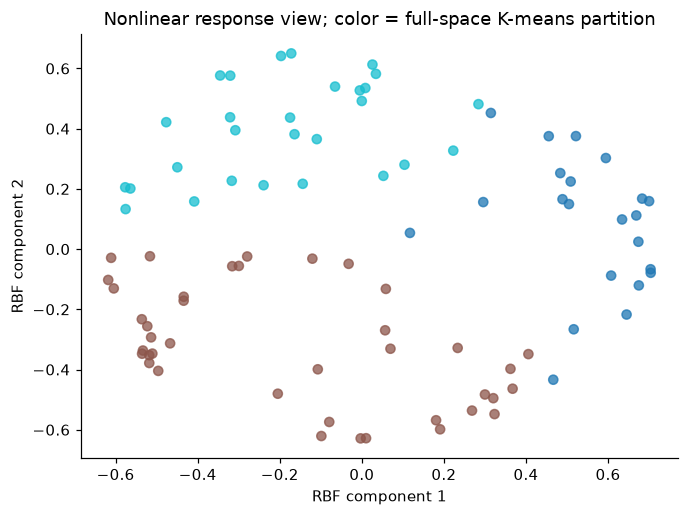

In [13]:
if structures is not None:
    print("Full-space versus display distance rank agreement:", structures["distance_rank_agreement"])
    embedding = structures["embedding"]
    plt.figure(figsize=(7, 5))
    plt.scatter(embedding.RBF1, embedding.RBF2, c=structures["labels"].kmeans, cmap="tab10", alpha=.75)
    plt.xlabel("RBF component 1")
    plt.ylabel("RBF component 2")
    plt.title("Nonlinear response view; color = full-space K-means partition")
    plt.show()

## 13. Explore explicit objective tradeoffs
**Question:** which observed profiles are not worse than another observed profile on every chosen objective?

Set `OBJECTIVE_DIRECTIONS` only after deciding which responses should be minimized or maximized. A profile dominates another when it is at least as good on every selected objective and strictly better on at least one. Duplicate profiles remain nondominated together if neither has a better competitor.

This frontier uses noisy observed means and only sampled alternatives. It is not a confidence-qualified or globally optimal frontier. More objectives often leave most alternatives nondominated. Correlated objectives may effectively duplicate a preference; omitted objectives and feasibility requirements must be considered separately. Confirm promising alternatives with additional runs before making decisions.

In [14]:
pareto = None
if OBJECTIVE_DIRECTIONS:
    pareto = pareto_profiles(means, OBJECTIVE_DIRECTIONS)
    display(means.join(pareto).sort_values("dominated_by"))
    objectives = list(OBJECTIVE_DIRECTIONS)
    if len(objectives) >= 2:
        plt.figure(figsize=(7, 5))
        for flag, label in [(False, "Dominated"), (True, "Nondominated across all selected objectives")]:
            subset = means.loc[pareto.nondominated == flag]
            plt.scatter(subset[objectives[0]], subset[objectives[1]], label=label, alpha=.7)
        plt.xlabel(objectives[0]); plt.ylabel(objectives[1]); plt.legend(fontsize=8)
        plt.title("Two-objective projection of the observed frontier")
        plt.show()
else:
    print("Tradeoff analysis skipped: specify objective directions in Setup.")

Tradeoff analysis skipped: specify objective directions in Setup.


## 14. Test whether a few extreme profiles drive the story
As a sensitivity analysis, exclude the top 5% of profiles by maximum absolute standardized response and recompute Pearson associations. This is a deliberately response-selected subset: changes are not evidence that these configurations are erroneous. Investigate their provenance and operating conditions before any removal. The original data and all primary results remain intact.

In [15]:
retained = extremeness <= extremeness.quantile(.95)
print("Configurations retained for sensitivity only:", int(retained.sum()), "of", len(retained))
if retained.sum() >= 4:
    display((active.loc[retained].corr() - result["pearson"]).rename_axis("Trimmed minus full Pearson"))
if EXPORT:
    relationships.to_csv(destination / "nonlinear_relationships.csv", index=False)
    conditional["partial"].to_csv(destination / "partial_correlations.csv")
    within["correlation"].to_csv(destination / "within_configuration_correlations.csv")
    if structures is not None:
        structures["comparison"].to_csv(destination / "alternative_cluster_methods.csv", index=False)
        structures["stability"].to_csv(destination / "subsampling_stability.csv", index=False)
        structures["labels"].to_csv(destination / "alternative_cluster_assignments.csv")
        structures["embedding"].to_csv(destination / "rbf_embedding.csv")
    if pareto is not None:
        means.join(pareto).to_csv(destination / "observed_objective_frontier.csv")

Configurations retained for sensitivity only: 85 of 90


,throughput,energy,delay,reliability
Trimmed minus full Pearson,,,,
throughput,0.000000,-0.008773,-0.021495,-0.060980
energy,-0.008773,0.000000,-0.019435,-0.039358
delay,-0.021495,-0.019435,0.000000,0.014532
reliability,-0.060980,-0.039358,0.014532,0.000000


## 15. Turn observations into questions for the next study
Record the response pair or profile, supporting evidence, sensitivity results, and a proposed follow-up—not merely a preferred plot.

| Observation | Useful follow-up |
|---|---|
| Strong distance correlation but weak Pearson/Spearman | Inspect curved response plots and investigate factor mechanisms |
| Marginal association weakens after linear adjustment | Investigate shared drivers without claiming mediation or causation |
| Strong within-run association | Examine paired simulation events and shared randomness |
| Clusters change across methods or subsamples | Treat profiles as a continuum; avoid declaring regimes |
| Promising nondominated profile has few runs | Replicate it and nearby competitors before selecting it |
| Association changes after extreme-profile exclusion | Verify those runs and investigate their operating conditions |

**Keep response exploration separate from surrogate validation.** Response-derived labels are unavailable at a new alternative and must not become predictors of those same responses. Use development-only outcomes if these findings influence model design; keep final-test outcomes untouched. This notebook does not establish factor sensitivity, causation, or predictive accuracy. Input-response modeling and fresh held-out evaluation remain separate tasks.

All saved example outputs are synthetic. The demonstration deliberately has continuous structure with no planted discrete regimes.